# Lesson 7 · Statistical Visualisation with Seaborn
### Distributions, comparisons, relationships, heatmaps and correlation: in a few lines

| | |
|---|---|
| **Type** | SOLUTIONS 07 |
| **Time** | about 120 minutes |
| **Level** | Intermediate |
| **Prerequisites** | Lesson 6 (Matplotlib) and Lesson 5 (groupby, pivot) |

**By the end of this notebook you will be able to:**

- Explain what Seaborn adds on top of Matplotlib and why *tidy (long) data* matters
- Draw distribution plots: histogram, KDE, ECDF, and compare groups
- Draw categorical plots: count, bar (with confidence intervals), box, violin, strip
- Draw relational plots with `hue`, `size`, `style` and facet into small multiples
- Visualise correlation: heatmaps, pair plots, joint plots, and read them *critically*
- Spot why correlation of trending series can fool you

## 🛠️ Setup (identical to the lesson notebook)

In [1]:

import sys; sys.path.insert(0, "..")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from course_utils import DATA_DIR, check, check_plot

sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams.update({"figure.figsize": (9, 4.5), "figure.dpi": 100})

prices = pd.read_csv(DATA_DIR / "market_prices_clean.csv", parse_dates=["date"])
prices["year"] = prices["date"].dt.year
prices["month"] = prices["date"].dt.month
weather = pd.read_json(DATA_DIR / "weather_monthly.json")

# A county-month panel for maize: price, volume and weather side by side
_mz = (prices[prices["crop"] == "Maize"].groupby(["county", "year", "month"], as_index=False)
       .agg(avg_price=("price_kes_per_kg", "mean"), volume_t=("volume_kg", lambda s: s.sum() / 1000)))
panel = _mz.merge(weather, on=["county", "year", "month"], how="left")
print("Setup complete ✔  prices", prices.shape, "| panel", panel.shape)


Setup complete ✔  prices (15048, 11) | panel (384, 7)


### 🎨 Problem 7.1: Tomato histogram by market type

Draw a **histogram of Tomatoes prices** (`bins=30`) from `prices`, with a **KDE curve** (`kde=True`) and **`hue='crop'`-free** (just tomatoes). Add a title.

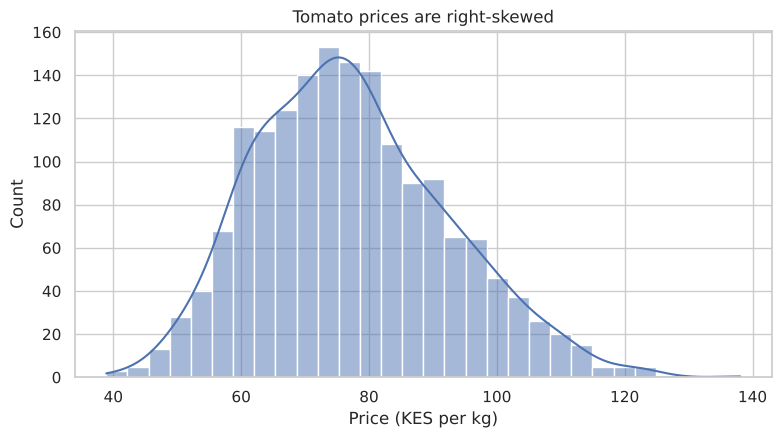

✅ 07-p1: your chart has the essentials. Now ask yourself: would a stranger understand it in 10 seconds?


True

In [2]:
t = prices[prices["crop"] == "Tomatoes"]
fig, ax = plt.subplots()
sns.histplot(data=t, x="price_kes_per_kg", bins=30, kde=True, ax=ax)
ax.set_title("Tomato prices are right-skewed")
ax.set_xlabel("Price (KES per kg)")
plt.show()

check_plot(ax, min_bars=30, name='07-p1')

### 🎨 Problem 7.2: Maize by county - box plot

Draw a **box plot** of **Maize** prices for each **county** (`x='county'`, `y='price_kes_per_kg'`) with a title, readable x tick labels (rotate them) and a y-label with units.

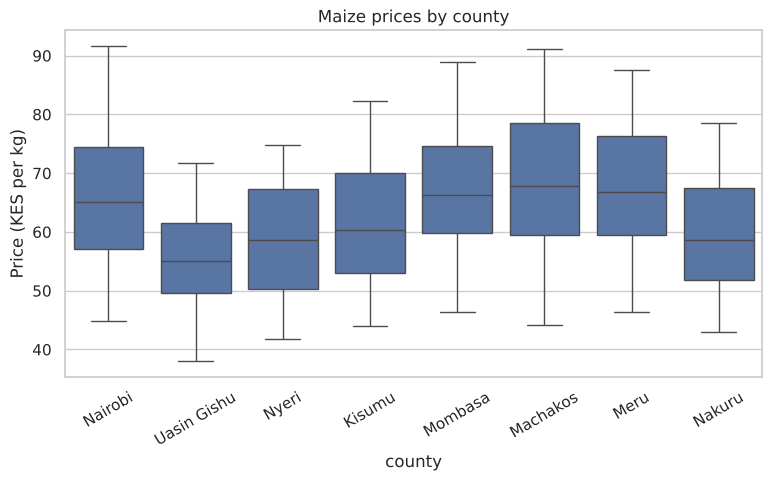

✅ 07-p2: your chart has the essentials. Now ask yourself: would a stranger understand it in 10 seconds?


True

In [3]:
mz = prices[prices["crop"] == "Maize"]
fig, ax = plt.subplots()
sns.boxplot(data=mz, x="county", y="price_kes_per_kg", ax=ax)
ax.tick_params(axis="x", rotation=30)
ax.set_title("Maize prices by county")
ax.set_ylabel("Price (KES per kg)")
plt.show()

check_plot(ax, min_lines=9, name='07-p2')

### 🎨 Problem 7.3: Bar chart with confidence intervals

Using `sns.barplot`, show the **mean price by crop** (x = crop). Give it a title and a y-label with units.

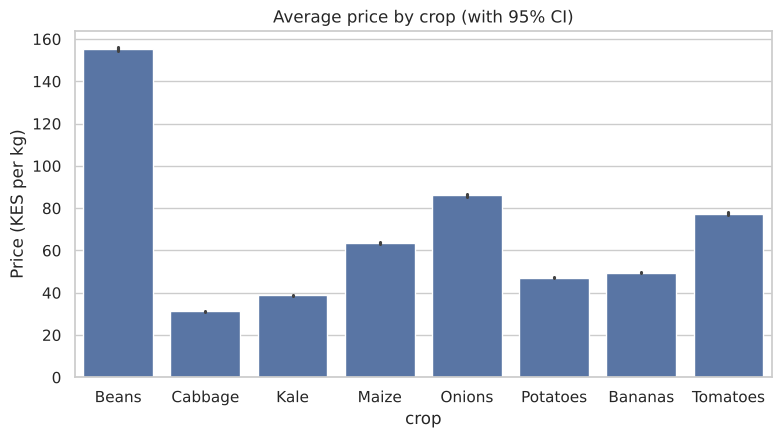

✅ 07-p3: your chart has the essentials. Now ask yourself: would a stranger understand it in 10 seconds?


True

In [4]:
fig, ax = plt.subplots()
sns.barplot(data=prices, x="crop", y="price_kes_per_kg", ax=ax)
ax.set_title("Average price by crop (with 95% CI)")
ax.set_ylabel("Price (KES per kg)")
plt.show()

check_plot(ax, min_bars=8, name='07-p3')

### 🎨 Problem 7.4: Price index lines

For **Maize, Beans and Tomatoes**, compute a price index where the **2021 mean of each crop = 100**, and draw **three lines** (one per crop, `hue='crop'`, `errorbar=None`) against `date`. Title, y-label and legend required.

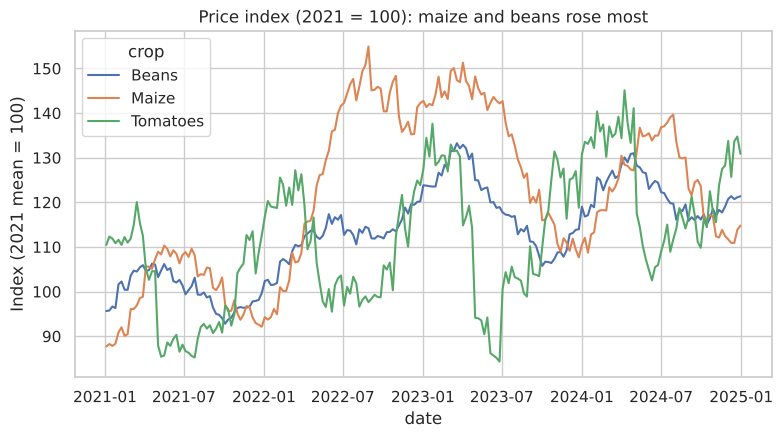

✅ 07-p4: your chart has the essentials. Now ask yourself: would a stranger understand it in 10 seconds?


True

In [5]:
d = prices[prices["crop"].isin(["Maize", "Beans", "Tomatoes"])].copy()
base = d[d["year"] == 2021].groupby("crop")["price_kes_per_kg"].mean()
d["index"] = d["price_kes_per_kg"] / d["crop"].map(base) * 100
fig, ax = plt.subplots()
sns.lineplot(data=d, x="date", y="index", hue="crop", errorbar=None, ax=ax)
ax.set_title("Price index (2021 = 100): maize and beans rose most")
ax.set_ylabel("Index (2021 mean = 100)")
plt.show()

check_plot(ax, n_lines=3, legend=True, name='07-p4')

### 🎨 Problem 7.5: Crop × year heatmap

Build a pivot table of **mean price** (rows = crop, columns = year) and draw it as an **annotated heatmap** (`annot=True`, `fmt='.0f'`, sequential colormap). Add a title.

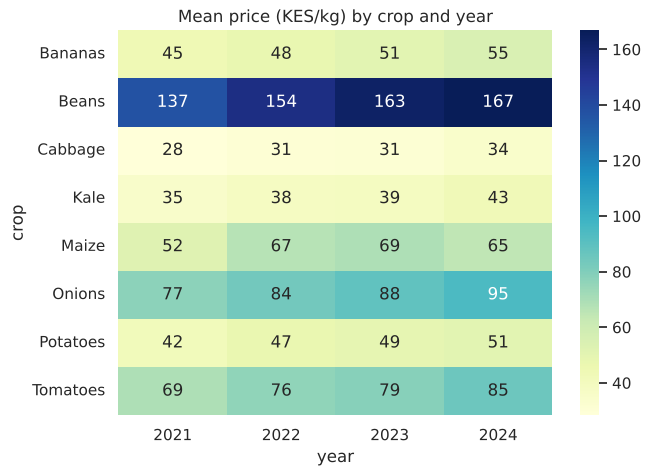

✅ 07-p5: your chart has the essentials. Now ask yourself: would a stranger understand it in 10 seconds?


True

In [6]:
pt = prices.pivot_table(index="crop", columns="year", values="price_kes_per_kg", aggfunc="mean")
fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(pt, annot=True, fmt=".0f", cmap="YlGnBu", ax=ax)
ax.set_title("Mean price (KES/kg) by crop and year")
plt.show()

check_plot(ax, name='07-p5')

### 🎨 Problem 7.6: Correlation heatmap of the maize panel

Compute the correlation matrix of `['avg_price', 'volume_t', 'rainfall_mm', 'avg_temp_c']` in `panel` and draw it as a heatmap with annotations, `cmap='coolwarm'`, `vmin=-1`, `vmax=1`. Add a title.

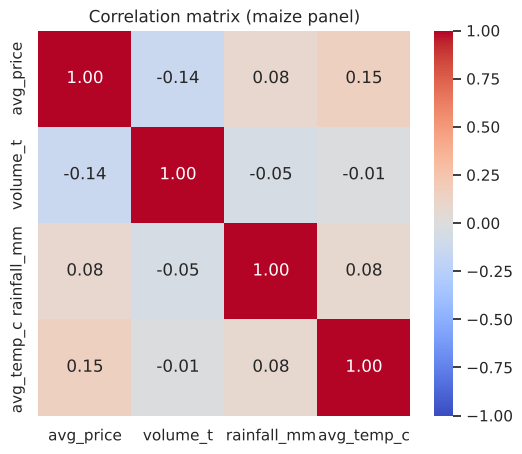

✅ 07-p6: your chart has the essentials. Now ask yourself: would a stranger understand it in 10 seconds?


True

In [7]:
cols = ["avg_price", "volume_t", "rainfall_mm", "avg_temp_c"]
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(panel[cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax)
ax.set_title("Correlation matrix (maize panel)")
plt.show()

check_plot(ax, xlabel=False, ylabel=False, name='07-p6')

### 🧩 Problem 7.7: Strongest correlate of price

In the `panel` DataFrame, which of the columns `volume_t`, `rainfall_mm`, `avg_temp_c` has the **largest absolute correlation** with `avg_price`? Return the column name.

*Expected type:* a string.

In [8]:
c = panel[["avg_price", "volume_t", "rainfall_mm", "avg_temp_c"]].corr()["avg_price"].drop("avg_price")
answer = c.abs().idxmax()

check('07-p7', answer)

✅ 07-p7: correct! Nicely done.


True

### 🎨 Problem 7.8: Regression plot

Draw a **`sns.regplot`** of **price (y) against volume in tonnes (x)** for **Kale at Wakulima Market**. Title and axis labels required.

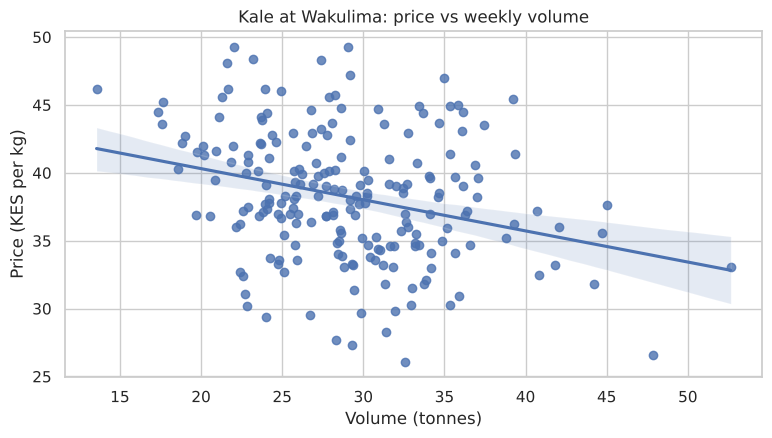

✅ 07-p8: your chart has the essentials. Now ask yourself: would a stranger understand it in 10 seconds?


True

In [9]:
k = prices[(prices["crop"] == "Kale") & (prices["market"] == "Wakulima Market")].copy()
k["volume_t"] = k["volume_kg"] / 1000
fig, ax = plt.subplots()
sns.regplot(data=k, x="volume_t", y="price_kes_per_kg", ax=ax)
ax.set_title("Kale at Wakulima: price vs weekly volume")
ax.set_xlabel("Volume (tonnes)"); ax.set_ylabel("Price (KES per kg)")
plt.show()

check_plot(ax, min_points=100, name='07-p8')

### ✍️ Problem 7.9: Levels vs changes

In section 5.3 almost every crop correlated moderately-to-strongly with every other in **price levels**, but the **weekly changes** told a more selective story (many pairs near zero, some negative, vegetables still positive). Explain *why* in 3–4 sentences, and say which version you would trust to decide whether *tomato prices help predict onion prices*.

**Model answer**

In levels, all prices share a **common upward trend** (food inflation, drought pressure), so any two trending series appear correlated even if week-to-week movements are unrelated. Differencing (or % change) removes the shared trend and keeps only the *short-term co-movement*: pairs with no real link fall toward zero, while pairs that react to the same shocks (e.g. vegetables sensitive to rainfall) stay positive. To judge whether one crop's price helps predict another's, trust the **changes** (and ideally lagged changes): the levels correlation is largely a shared clock.